# scNOMe-HiC sequencing saturation (GM12878, s7 supplemental)

Collects the per-`(cell, fraction)` saturation results produced by the SLURM
array (`code/run_one.sh`) and plots saturation curves for four metrics:

| metric | meaning |
|--------|---------|
| `HCG_loci` | CpG-methylation positions detected (Bis-SNP `HCG.6plus2.bed` rows) |
| `GCH_loci` | GpC-accessibility positions detected (`GCH.6plus2.bed` rows) |
| `cis` | intra-chromosomal contacts, mapQ30 + dedup (`UniqMappedMapQ30NoPcrCis`) |
| `cis_1kb` | cis contacts spanning > 1 kb (`...CisMore1kb`) |

Reads were subsampled from the **pre-dedup** mapped BAM and de-duplication was
re-run at each depth (fixed `samtools -s` seed -> nested subsets), so the curves
show the true PCR-duplicate-driven saturation. 180 QC-passing cells x
{0.05, 0.1, 0.2, 0.4, 0.6, 0.8} + 1.0 (existing pipeline output).

In [1]:
# --- environment ---------------------------------------------------------------
# This notebook was written against the `scnomehic` conda environment.
#     conda env create -f env/scnomehic.yml && conda activate scnomehic
# See env/README.md for which notebook uses which environment.
_ENV_EXPECTED = "scnomehic"
import os as _os, sys as _sys
if _os.path.basename(_sys.prefix) != _ENV_EXPECTED:
    print(f"[env] expected the '{_ENV_EXPECTED}' environment, running in "
          f"'{_os.path.basename(_sys.prefix)}' ({_sys.prefix}). See env/README.md.",
          file=_sys.stderr)

# --- repo paths: edit paths.yaml at the repository root, not this notebook ---
# Cached so that re-running this cell still works after it has chdir'd away.
import os as _os, sys as _sys
if "REPO_ROOT" not in globals():
    _r = _os.getcwd()
    while _r != "/" and not _os.path.exists(_os.path.join(_r, "paths.py")):
        _r = _os.path.dirname(_r)
    assert _os.path.exists(_os.path.join(_r, "paths.py")), \
        "paths.py not found above the working directory -- start Jupyter inside the repository"
    REPO_ROOT = _r
_sys.path.insert(0, REPO_ROOT)
from paths import DATA, REFERENCE, SOFTWARE, WORK, TMP, CONDA_SH, CONDA_ENVS

import glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# publication-level font sizes (apply to every figure below)
plt.rcParams.update({
    'font.size':        14,
    'axes.titlesize':   19,
    'axes.labelsize':   16,
    'xtick.labelsize':  14,
    'ytick.labelsize':  14,
    'legend.fontsize':  14,
    'figure.titlesize': 21,
})

RESULTS_DIR = WORK + '/analysis/s7/results'
FIG_DIR     = WORK + '/analysis/s7/figures'
os.makedirs(FIG_DIR, exist_ok=True)
COLS = ['cell','fraction','seed','total_frags','mapq30','nodup','cis','cis_1kb','GCH_loci','HCG_loci']

## 1. Collect all per-(cell, fraction) result lines

In [2]:
files = sorted(glob.glob(os.path.join(RESULTS_DIR, '*.tsv')))
rows = []
for f in files:
    with open(f) as fh:
        line = fh.readline().strip()
    if line:
        rows.append(line.split('\t'))
df = pd.DataFrame(rows, columns=COLS)
for c in COLS:
    if c != 'cell':
        df[c] = pd.to_numeric(df[c], errors='coerce')
df = df.sort_values(['cell','fraction']).reset_index(drop=True)
print(f'{len(files)} result files  ->  {df.shape[0]} rows')
print(f"{df['cell'].nunique()} cells x {sorted(df['fraction'].unique())} fractions")
# save a flat table next to the code
df.to_csv(WORK + '/analysis/s7/code/saturation_results.tsv', sep='\t', index=False)
df.head()

1260 result files  ->  1260 rows
180 cells x [np.float64(0.05), np.float64(0.1), np.float64(0.2), np.float64(0.4), np.float64(0.6), np.float64(0.8), np.float64(1.0)] fractions


,cell,fraction,seed,total_frags,mapq30,nodup,cis,cis_1kb,GCH_loci,HCG_loci
0,scNH_GM_4plex_10_S9.ATCACG,0.05,42,475501,346454,315398,307771,8478,2487672,373824
1,scNH_GM_4plex_10_S9.ATCACG,0.10,42,951554,692751,579214,565377,15557,4454390,667246
2,scNH_GM_4plex_10_S9.ATCACG,0.20,42,1900411,1384174,996139,972718,25943,7327021,1095637
3,scNH_GM_4plex_10_S9.ATCACG,0.40,42,3800767,2769618,1563067,1527738,39442,10743596,1603118
4,scNH_GM_4plex_10_S9.ATCACG,0.60,42,5700680,4155328,1935517,1892747,47510,12633397,1884097


## 2. Completeness + sanity checks
Expect 180 cells x 7 depths = 1260 rows. Metrics must increase with depth;
the unique fraction (`nodup`/`mapq30`) must *fall* with depth (more duplicates).

In [3]:
exp_cells, exp_frac = 180, 7
print('rows:', df.shape[0], '/', exp_cells*exp_frac)
missing = exp_cells*exp_frac - df.shape[0]
print('missing rows:', missing)
# per-cell depth coverage (should all be 7)
depth_counts = df.groupby('cell')['fraction'].nunique()
print('cells with <7 depths:', (depth_counts < exp_frac).sum())

summary = df.groupby('fraction').agg(
    n=('cell','size'),
    total_frags=('total_frags','median'),
    uniq_frac=('nodup', lambda s: (s / df.loc[s.index,'mapq30']).median()),
    cis=('cis','median'),
    cis_1kb=('cis_1kb','median'),
    GCH_loci=('GCH_loci','median'),
    HCG_loci=('HCG_loci','median'),
)
summary

rows: 1260 / 1260
missing rows: 0
cells with <7 depths: 0


,n,total_frags,uniq_frac,cis,cis_1kb,GCH_loci,HCG_loci
fraction,,,,,,,
0.05,180,240711.5,0.928859,146720.0,4056.0,1163839.0,171648.5
0.10,180,480938.0,0.867537,276080.0,7475.5,2137850.0,317117.5
0.20,180,961157.0,0.767318,480817.5,13159.5,3626221.5,544065.0
0.40,180,1922549.0,0.624212,780692.0,21047.0,5531722.0,827708.0
0.60,180,2883724.5,0.527715,985612.0,25588.5,6711384.0,995414.5
0.80,180,3845422.0,0.457858,1132317.5,29128.5,7568540.5,1130074.5
1.00,180,4805965.0,0.405407,1257403.0,31925.0,8184558.0,1254864.0


## 3. Saturation curves + Michaelis-Menten fit
Per-cell observed curves (faint), the cross-cell median (points), and a
Michaelis-Menten saturation fit `y = Ymax·N/(N+K)` to the median. Annotations
give the fitted asymptote `Ymax`, half-saturation `K`, and **% saturation at
full depth = N/(N+K)**.

saved /gpfs/projects/b1198/epifluidlab/yoshii/scnomehic_paper/s7/figures/s7_saturation.{pdf,png}


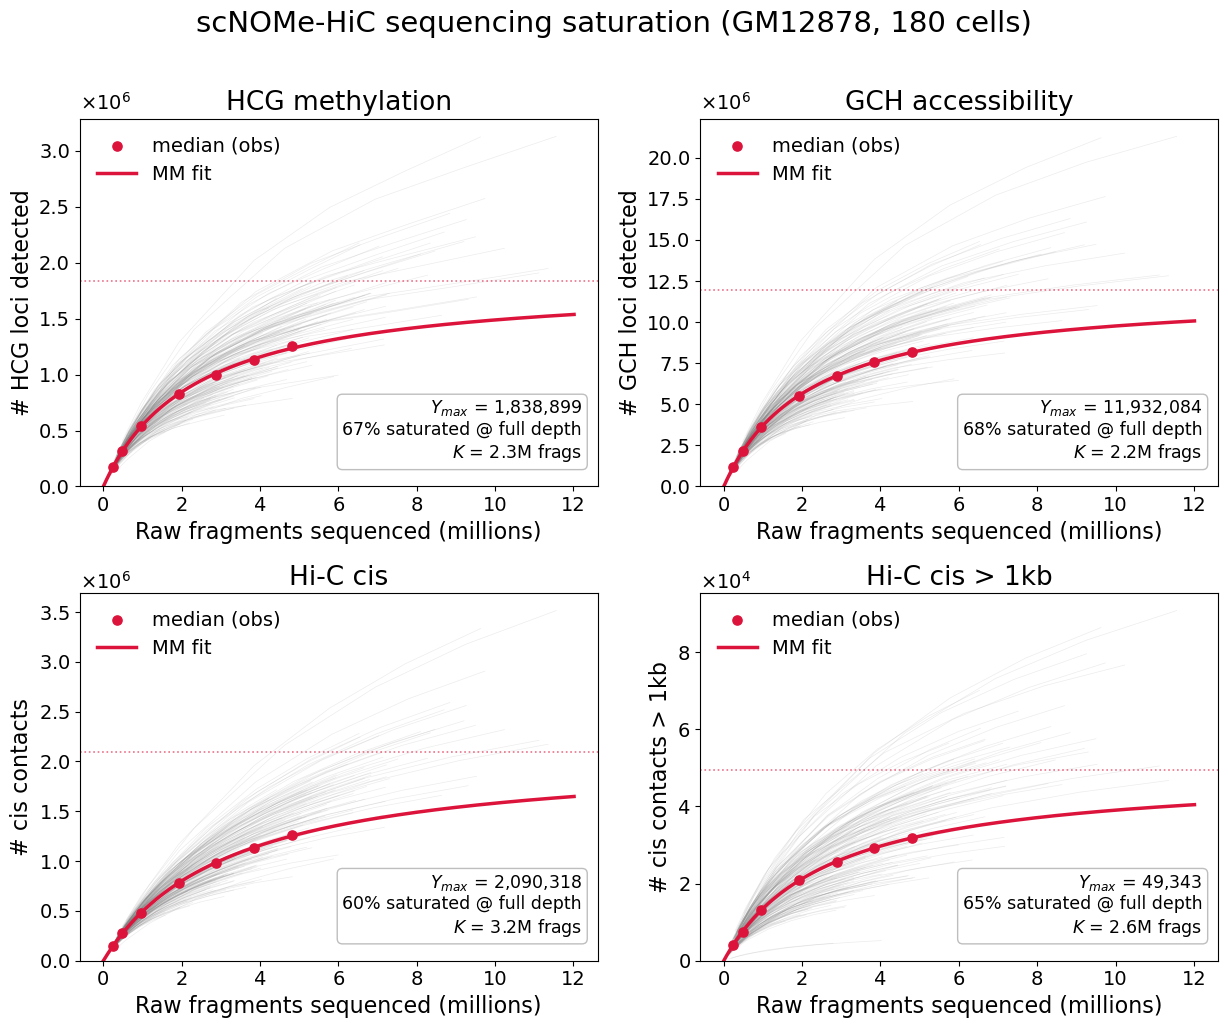

In [4]:
from scipy.optimize import curve_fit

# Michaelis-Menten / rectangular-hyperbola saturation model:
#   y = Ymax * N / (N + K)
def mm(N, Ymax, K):
    return Ymax * N / (N + K)

# (col, ylabel, title, yscale)  -- yscale=1e6 forces the loci panels onto a 10^6 axis
panels = [
    ('HCG_loci', '# HCG loci detected',  'HCG methylation',   1e6),
    ('GCH_loci', '# GCH loci detected',  'GCH accessibility', 1e6),
    ('cis',      '# cis contacts',       'Hi-C cis',          None),
    ('cis_1kb',  '# cis contacts > 1kb', 'Hi-C cis > 1kb',    None),
]
fit_rows = []
fig, axes = plt.subplots(2, 2, figsize=(12.5, 10.5))
for ax, (col, ylab, title, scale) in zip(axes.ravel(), panels):
    s = scale if scale else 1.0
    # faint per-cell observed curves
    for cell, g in df.groupby('cell'):
        g = g.sort_values('total_frags')
        ax.plot(g['total_frags']/1e6, g[col]/s, color='gray', alpha=0.15, lw=0.5)
    # median + MM fit (fit on raw values, plot scaled)
    med = df.groupby('fraction').agg(x=('total_frags','median'), y=(col,'median')).sort_values('x')
    N, y = med['x'].values, med['y'].values
    p, _ = curve_fit(mm, N, y, p0=[y.max()*1.5, N.mean()], maxfev=20000)
    Ymax, K = p; Nfull = N.max(); sat = Nfull/(Nfull+K)
    fit_rows.append((title, col, Ymax, K, sat))
    ax.scatter(N/1e6, y/s, color='crimson', s=44, zorder=5, label='median (obs)')
    xs = np.linspace(0, N.max()*2.5, 300)
    ax.plot(xs/1e6, mm(xs, *p)/s, color='crimson', lw=2.5, label='MM fit')
    ax.axhline(Ymax/s, color='crimson', ls=':', lw=1.2, alpha=0.6)
    ax.text(0.97, 0.06,
            f"$Y_{{max}}$ = {Ymax:,.0f}\n{sat*100:.0f}% saturated @ full depth\n$K$ = {K/1e6:.1f}M frags",
            transform=ax.transAxes, ha='right', va='bottom', fontsize=12.5,
            bbox=dict(boxstyle='round', fc='white', ec='0.7', alpha=0.85))
    ax.set_xlabel('Raw fragments sequenced (millions)')
    ax.set_ylabel(ylab); ax.set_title(title)
    ax.set_ylim(bottom=0)
    if scale:                                   # loci panels: fixed 10^6 axis, mathtext label upper-left
        ax.text(0.0, 1.015, r'$\times 10^{6}$', transform=ax.transAxes, fontsize=14, va='bottom', ha='left')
    else:                                       # Hi-C panels: auto sci, but render as x10^n (not 1en)
        ax.ticklabel_format(axis='y', style='sci', scilimits=(0,0), useMathText=True)
        ax.yaxis.get_offset_text().set_fontsize(14)
    ax.legend(frameon=False, loc='upper left')
fig.suptitle(f"scNOMe-HiC sequencing saturation (GM12878, {df['cell'].nunique()} cells)")
fig.tight_layout(rect=[0,0,1,0.97])
for ext in ('pdf','png'):
    fig.savefig(os.path.join(FIG_DIR, f's7_saturation.{ext}'), dpi=200)
print('saved', os.path.join(FIG_DIR, 's7_saturation.{pdf,png}'))
plt.show()

In [5]:
# Fit summary: median-curve parameters + per-cell %saturation distribution.
fit = pd.DataFrame(fit_rows, columns=['panel','metric','Ymax','K_frags','pct_sat_full'])
fit['pct_sat_full'] = (fit['pct_sat_full']*100).round(1)
fit['Ymax'] = fit['Ymax'].round(0)
fit['K_Mfrags'] = (fit['K_frags']/1e6).round(2)
print('Median-curve Michaelis-Menten fit:')
print(fit[['metric','Ymax','K_Mfrags','pct_sat_full']].to_string(index=False))
fit.to_csv(WORK + '/analysis/s7/code/saturation_fit_summary.tsv', sep='\t', index=False)

# Per-cell fit -> distribution of %saturation at each cell's own full depth.
print('\nPer-cell %saturation at full depth (median [IQR]):')
for col, lab in [('GCH_loci','GCH'),('HCG_loci','HCG'),('cis','cis'),('cis_1kb','cis>1kb')]:
    sats = []
    for cell, g in df.groupby('cell'):
        g = g.sort_values('total_frags'); Nc, yc = g['total_frags'].values, g[col].values
        if len(Nc) < 4 or yc.max() <= 0:
            continue
        try:
            pc, _ = curve_fit(mm, Nc, yc, p0=[yc.max()*1.5, Nc.mean()], maxfev=20000)
            sats.append(Nc.max()/(Nc.max()+pc[1]))
        except Exception:
            pass
    s = np.array(sats)*100
    print(f"  {lab:7} {np.median(s):.1f}%  [{np.percentile(s,25):.1f}, {np.percentile(s,75):.1f}]  (n={len(s)})")

Median-curve Michaelis-Menten fit:
  metric       Ymax  K_Mfrags  pct_sat_full
HCG_loci  1838899.0      2.35          67.2
GCH_loci 11932084.0      2.22          68.4
     cis  2090318.0      3.22          59.9
 cis_1kb    49343.0      2.64          64.5

Per-cell %saturation at full depth (median [IQR]):
  GCH     67.6%  [63.2, 69.9]  (n=180)
  HCG     66.6%  [62.3, 69.1]  (n=180)
  cis     58.6%  [54.2, 60.6]  (n=180)


  cis>1kb 64.7%  [61.3, 66.4]  (n=180)


## 4. Library-complexity view (unique molecules vs raw fragments)
A flattening curve here is the direct read-out of saturation: as more raw
fragments are sequenced, fewer of them are new (unique) molecules.

saved /gpfs/projects/b1198/epifluidlab/yoshii/scnomehic_paper/s7/figures/s7_library_complexity.{pdf,png}


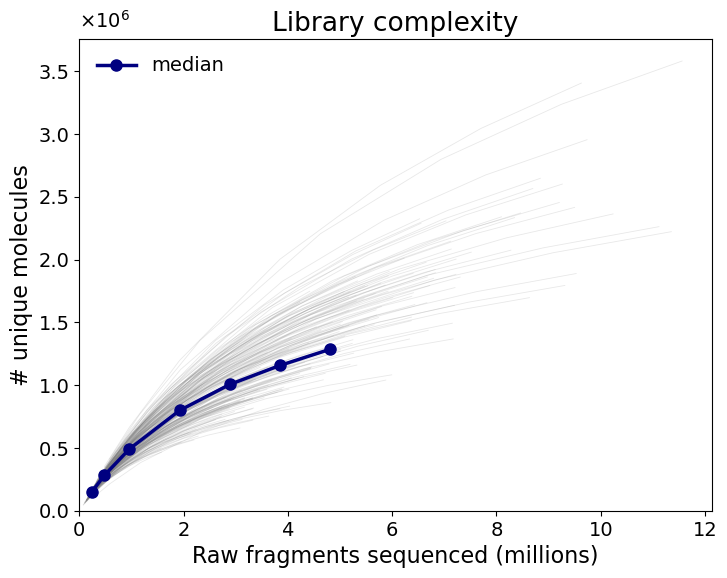

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 6))
for cell, g in df.groupby('cell'):
    g = g.sort_values('total_frags')
    ax.plot(g['total_frags']/1e6, g['nodup']/1e6, color='gray', alpha=0.18, lw=0.6)
med = df.groupby('fraction').agg(x=('total_frags','median'), y=('nodup','median')).sort_values('x')
ax.plot(med['x']/1e6, med['y']/1e6, color='navy', lw=2.5, marker='o', ms=8, label='median')
ax.set_xlabel('Raw fragments sequenced (millions)')
ax.set_ylabel('# unique molecules')
ax.set_title('Library complexity')
ax.set_ylim(bottom=0); ax.set_xlim(left=0)
ax.text(0.0, 1.015, r'$\times 10^{6}$', transform=ax.transAxes, fontsize=14, va='bottom', ha='left')
ax.legend(frameon=False, loc='upper left')
fig.tight_layout()
for ext in ('pdf','png'):
    fig.savefig(os.path.join(FIG_DIR, f's7_library_complexity.{ext}'), dpi=200)
print('saved', os.path.join(FIG_DIR, 's7_library_complexity.{pdf,png}'))
plt.show()

## 5. Saturation curves with x = subsample fraction
Same four metrics, but the x-axis is the **subsample fraction** (0.05 … 1.0)
instead of raw fragments. All cells share identical x positions, so the median
is taken straight down each fraction. MM fit here is `y = Ymax·f/(f+k)`, and
% saturation at full depth = `1/(1+k)`.

saved /gpfs/projects/b1198/epifluidlab/yoshii/scnomehic_paper/s7/figures/s7_saturation_byfraction.{pdf,png}


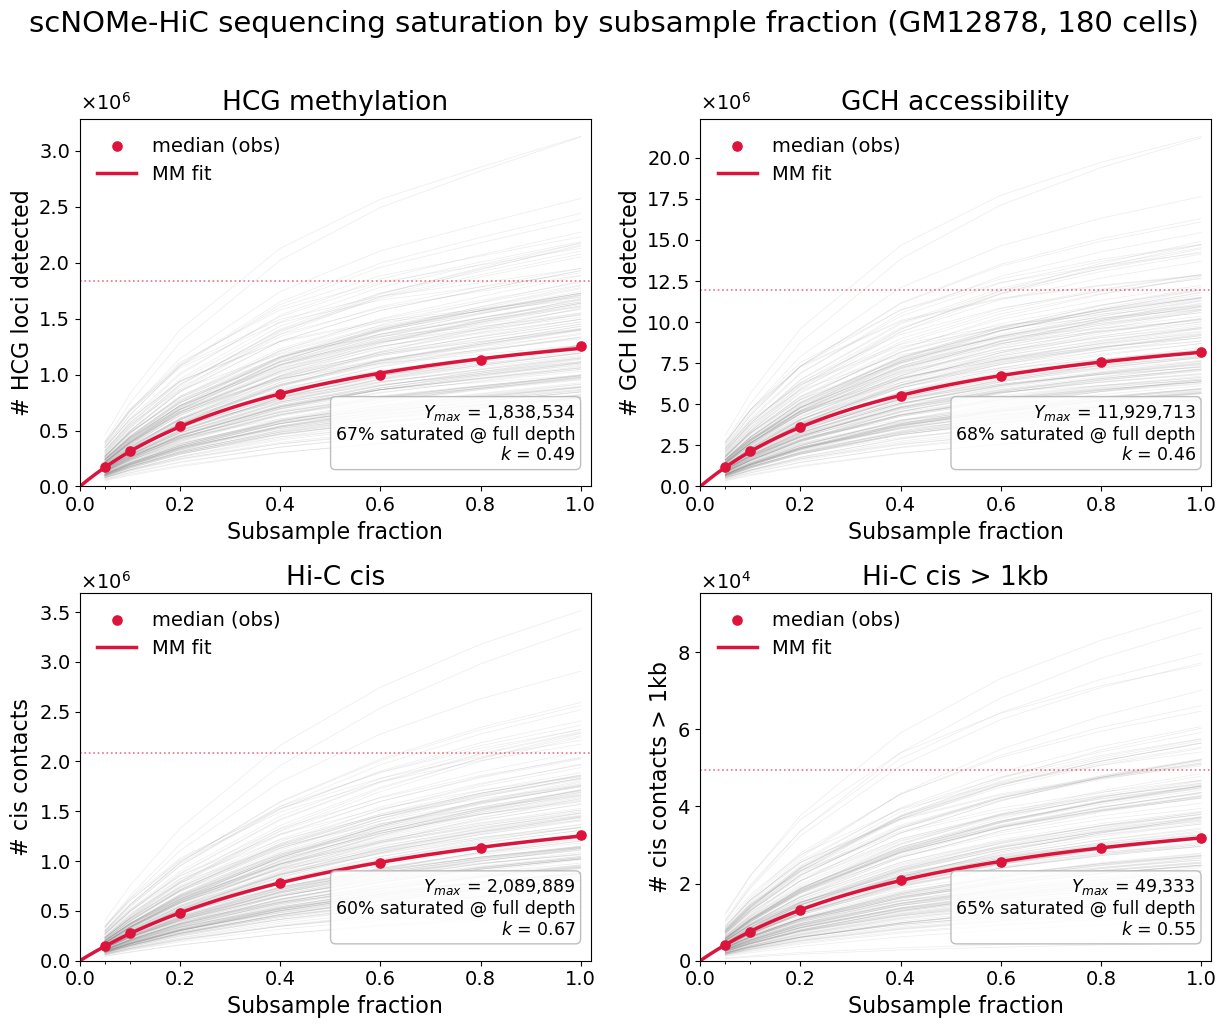

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12.5, 10.5))
for ax, (col, ylab, title, scale) in zip(axes.ravel(), panels):
    s = scale if scale else 1.0
    # faint per-cell curves (x = fraction; all cells aligned on the same 7 x-values)
    for cell, g in df.groupby('cell'):
        g = g.sort_values('fraction')
        ax.plot(g['fraction'], g[col]/s, color='gray', alpha=0.15, lw=0.5)
    # median straight down each fraction
    med = df.groupby('fraction')[col].median()
    f, y = med.index.values, med.values
    ax.scatter(f, y/s, color='crimson', s=44, zorder=5, label='median (obs)')
    # MM fit in fraction space: y = Ymax * f / (f + k)
    p, _ = curve_fit(mm, f, y, p0=[y.max()*1.5, 0.5], maxfev=20000)
    Ymax, k = p; sat = 1.0/(1.0+k)
    xs = np.linspace(0, 1.0, 200)
    ax.plot(xs, mm(xs, *p)/s, color='crimson', lw=2.5, label='MM fit')
    ax.axhline(Ymax/s, color='crimson', ls=':', lw=1.2, alpha=0.6)
    ax.text(0.97, 0.06,
            f"$Y_{{max}}$ = {Ymax:,.0f}\n{sat*100:.0f}% saturated @ full depth\n$k$ = {k:.2f}",
            transform=ax.transAxes, ha='right', va='bottom', fontsize=12.5,
            bbox=dict(boxstyle='round', fc='white', ec='0.7', alpha=0.85))
    ax.set_xlabel('Subsample fraction')
    ax.set_ylabel(ylab); ax.set_title(title)
    ax.set_xlim(0, 1.02); ax.set_ylim(bottom=0)
    ax.set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
    ax.set_xticks(sorted(df['fraction'].unique()), minor=True)
    if scale:
        ax.text(0.0, 1.015, r'$\times 10^{6}$', transform=ax.transAxes, fontsize=14, va='bottom', ha='left')
    else:
        ax.ticklabel_format(axis='y', style='sci', scilimits=(0,0), useMathText=True)
        ax.yaxis.get_offset_text().set_fontsize(14)
    ax.legend(frameon=False, loc='upper left')
fig.suptitle(f"scNOMe-HiC sequencing saturation by subsample fraction (GM12878, {df['cell'].nunique()} cells)")
fig.tight_layout(rect=[0,0,1,0.97])
for ext in ('pdf','png'):
    fig.savefig(os.path.join(FIG_DIR, f's7_saturation_byfraction.{ext}'), dpi=200)
print('saved', os.path.join(FIG_DIR, 's7_saturation_byfraction.{pdf,png}'))
plt.show()